# 05 · P1: a quina edat s'espatllen i a quina arriben a final de vida

Resposta: `edat_neta`, l'edat el dia de la reparació. **És l'edat dels mòbils que s'espatllen i arriben a un Repair Café, no la vida útil.**

1. Resposta descriptiva: medianes amb interval de confiança per *bootstrap* agrupat per grup de reparació.
2. Model: regressió quantílica de la mediana amb el tipus d'avaria, la marca, l'any i el proveïdor (apartat 5.1 del disseny).

In [1]:
import sys
sys.path.insert(0, "..")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from patsy import dmatrices
from sklearn.linear_model import QuantileRegressor

import comu

rng = np.random.default_rng(42)
dades = comu.carrega_classificats().dropna(subset=["edat_neta"]).copy()
dades["marca"] = comu.agrupa_rars(dades["marca"])
dades["data_provider"] = comu.agrupa_rars(dades["data_provider"])
dades["anys_des_2020"] = dades["any_event"] - 2020
print(f"Registres amb edat: {len(dades):,} en {dades['group_identifier'].nunique()} grups de reparació")

Registres amb edat: 1,694 en 299 grups de reparació


In [2]:
def mediana_ic(df, n_boot=1000):
    """Mediana i IC 95 % per bootstrap agrupat per grup de reparació."""
    grups = df.groupby("group_identifier")["edat_neta"].apply(np.asarray)
    valors = list(grups.values)
    boots = []
    for _ in range(n_boot):
        tria = rng.integers(0, len(valors), len(valors))
        boots.append(np.median(np.concatenate([valors[i] for i in tria])))
    return pd.Series({"n": len(df), "mediana": df["edat_neta"].median(),
                      "ic_inf": np.percentile(boots, 2.5), "ic_sup": np.percentile(boots, 97.5)})

## Edat a la reparació i a final de vida

In [3]:
estat = {"Fixed": "Reparat", "Repairable": "Reparable", "End of life": "Final de vida"}
taula = pd.concat(
    {"Tots": mediana_ic(dades)} |
    {estat[e]: mediana_ic(g) for e, g in dades.groupby("repair_status")}, axis=1).T
taula

,n,mediana,ic_inf,ic_sup
Tots,1694.0,4.0,3.0,4.0
Final de vida,225.0,5.0,4.0,5.0
Reparat,907.0,4.0,3.0,4.0
Reparable,562.0,3.0,3.0,4.0


## Per tipus d'avaria

,n,mediana,ic_inf,ic_sup
grup_avaria,,,,
Altres,130.0,3.0,2.5,4.00000
Botons i connectors,69.0,3.0,3.0,5.00000
Programari i configuració,203.0,3.0,3.0,4.00000
Pantalla,336.0,3.0,3.0,3.50625
Port de càrrega,92.0,4.0,3.0,5.00000
Desconegut,625.0,4.0,4.0,4.00000
Bateria i alimentació,213.0,5.0,4.0,5.00000


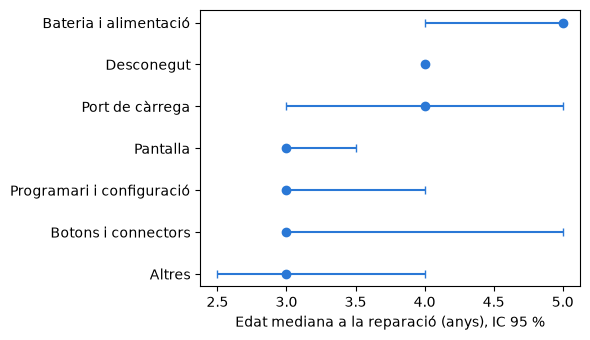

In [4]:
per_avaria = (dades.groupby("grup_avaria").filter(lambda g: len(g) >= 30)
              .groupby("grup_avaria").apply(mediana_ic).sort_values("mediana"))
display(per_avaria)
fig, ax = plt.subplots(figsize=(6, 3.5))
y = np.arange(len(per_avaria))
ax.errorbar(per_avaria["mediana"], y, xerr=[per_avaria["mediana"] - per_avaria["ic_inf"],
            per_avaria["ic_sup"] - per_avaria["mediana"]], fmt="o", color="#2a78d6", capsize=3)
ax.set_yticks(y, per_avaria.index)
ax.set_xlabel("Edat mediana a la reparació (anys), IC 95 %")
plt.tight_layout(); plt.show()

## Model: regressió quantílica

Referències: pantalla, Apple, The Restart Project i l'any 2020 (`anys_des_2020`). L'edat ve gairebé sempre en anys sencers; per tractar els empats, sumem un soroll uniforme U(0, 1) i fem la mitjana de 20 ajustos [@machado2005]. Els coeficients es llegeixen, aproximadament, com a anys de diferència en la mediana. L'ajust és exacte (programació lineal amb `QuantileRegressor` de scikit-learn, sense penalització).

In [5]:
def noms(index):
    return index.str.replace(r"C\((\w+), Treatment\('[^']+'\)\)\[T\.(.+)\]", r"\1: \2", regex=True)

FORMULA = ("edat_j ~ C(grup_avaria, Treatment('Pantalla')) + C(marca, Treatment('Apple'))"
           " + anys_des_2020 + C(data_provider, Treatment('The Restart Project'))")

def ajusta(df, q=0.5, n_jitter=20):
    y, X = dmatrices(FORMULA, df.assign(edat_j=df["edat_neta"]), return_type="dataframe")
    params = []
    for _ in range(n_jitter):
        y_j = y.iloc[:, 0] + rng.uniform(0, 1, len(y))
        qr = QuantileRegressor(quantile=q, alpha=0, fit_intercept=False, solver="highs").fit(X, y_j)
        params.append(pd.Series(qr.coef_, index=X.columns))
    return pd.concat(params, axis=1).mean(axis=1)

def bootstrap(df, q=0.5, n_boot=200):
    grups = df["group_identifier"].unique()
    per_grup = dict(tuple(df.groupby("group_identifier")))
    res = []
    for _ in range(n_boot):
        tria = rng.choice(grups, len(grups))
        d = pd.concat([per_grup[g] for g in tria], ignore_index=True)
        res.append(ajusta(d, q, n_jitter=1))
    return pd.concat(res, axis=1)

def taula_q(df, q):
    est = ajusta(df, q)
    boot = bootstrap(df, q).reindex(est.index)
    return pd.DataFrame({"coef": est, "ic_inf": boot.quantile(0.025, axis=1),
                         "ic_sup": boot.quantile(0.975, axis=1)})

q50 = taula_q(dades, 0.5)
q50.set_axis(noms(q50.index)).round(2)

,coef,ic_inf,ic_sup
Intercept,3.38,3.17,3.77
grup_avaria: Altres,0.21,-0.25,0.62
grup_avaria: Bateria i alimentació,1.25,0.90,1.75
grup_avaria: Botons i connectors,0.59,0.06,1.24
grup_avaria: Danys interns i aigua,0.00,-0.60,0.86
grup_avaria: Desconegut,0.57,0.20,1.02
grup_avaria: Port de càrrega,0.36,-0.19,1.09
grup_avaria: Programari i configuració,-0.25,-0.77,0.66
marca: Altres,-0.21,-0.82,0.40
marca: Desconeguda,-0.74,-1.23,0.10


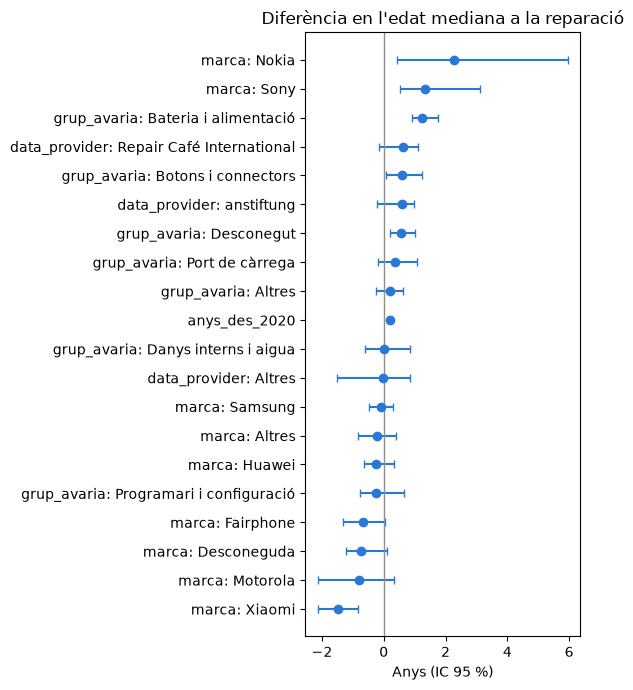

In [6]:
def grafic_coef(t, titol, xlabel):
    t = t.drop("Intercept").copy()
    t.index = noms(t.index)
    t = t.sort_values("coef")
    fig, ax = plt.subplots(figsize=(6, 0.3 * len(t) + 1))
    y = np.arange(len(t))
    ax.errorbar(t["coef"], y, xerr=[t["coef"] - t["ic_inf"], t["ic_sup"] - t["coef"]],
                fmt="o", color="#2a78d6", capsize=3)
    ax.axvline(0, color="#8f8e89", lw=1)
    ax.set_yticks(y, t.index)
    ax.set_xlabel(xlabel); ax.set_title(titol)
    plt.tight_layout(); plt.show()

grafic_coef(q50, "Diferència en l'edat mediana a la reparació", "Anys (IC 95 %)")

## Quartils 25 i 75

Un factor pot avançar les fallades primerenques i no les tardanes, o a l'inrevés.

In [7]:
quartils = pd.DataFrame({q: ajusta(dades, q) for q in (0.25, 0.5, 0.75)})
quartils.index = noms(quartils.index)
quartils.round(2)

,0.25,0.50,0.75
Intercept,2.55,3.37,4.50
grup_avaria: Altres,-0.04,0.21,0.54
grup_avaria: Bateria i alimentació,1.22,1.26,1.64
grup_avaria: Botons i connectors,0.22,0.57,0.64
grup_avaria: Danys interns i aigua,0.18,-0.05,1.01
grup_avaria: Desconegut,0.14,0.57,0.86
grup_avaria: Port de càrrega,0.01,0.38,1.28
grup_avaria: Programari i configuració,-0.71,-0.21,0.53
marca: Altres,-0.44,-0.22,-0.04
marca: Desconeguda,-0.43,-0.71,-0.86


## Comprovació: regressió log-normal

Efecte en percentatge sobre l'edat, amb errors agrupats per grup de reparació.

In [8]:
ln = smf.ols(FORMULA.replace("edat_j", "np.log(edat_neta + 0.5)"), dades).fit(
    cov_type="cluster", cov_kwds={"groups": pd.factorize(dades["group_identifier"])[0]})
pct = pd.DataFrame({"efecte_%": (np.exp(ln.params) - 1) * 100,
                    "ic_inf_%": (np.exp(ln.conf_int()[0]) - 1) * 100,
                    "ic_sup_%": (np.exp(ln.conf_int()[1]) - 1) * 100,
                    "p": ln.pvalues}).drop("Intercept")
pct.index = noms(pct.index)
pct.round(3)

,efecte_%,ic_inf_%,ic_sup_%,p
grup_avaria: Altres,5.950,-4.541,17.594,0.277
grup_avaria: Bateria i alimentació,34.597,23.243,46.997,0.000
grup_avaria: Botons i connectors,6.150,-7.838,22.261,0.408
grup_avaria: Danys interns i aigua,11.888,-4.344,30.874,0.160
grup_avaria: Desconegut,14.551,6.269,23.479,0.000
grup_avaria: Port de càrrega,12.780,-2.059,29.867,0.095
grup_avaria: Programari i configuració,-9.242,-22.672,6.519,0.235
marca: Altres,-8.033,-19.386,4.918,0.213
marca: Desconeguda,-15.165,-26.715,-1.794,0.028
marca: Fairphone,-16.210,-29.806,0.019,0.050


## Sensibilitat: només els tipus d'avaria classificats per persones (MobiFix)

In [9]:
nomes_mf = dades[dades["font_avaria"] == "MobiFix"]
print(f"Registres: {len(nomes_mf):,}")
sens = ajusta(nomes_mf)
t = pd.DataFrame({"tots": q50["coef"], "només MobiFix": sens})
t.index = noms(t.index)
t.round(2)

Registres: 356


,tots,només MobiFix
data_provider: Altres,-0.02,NaN
data_provider: Repair Café International,0.62,NaN
data_provider: anstiftung,0.58,0.87
grup_avaria: Altres,0.21,0.41
grup_avaria: Bateria i alimentació,1.25,1.10
grup_avaria: Botons i connectors,0.59,-0.01
grup_avaria: Danys interns i aigua,0.00,-0.20
grup_avaria: Desconegut,0.57,1.57
grup_avaria: Port de càrrega,0.36,0.30
grup_avaria: Programari i configuració,-0.25,0.63
